# Cuaderno 01 · Análisis exploratorio y limpieza de datos
## Predicción de enfermedad cardiovascular — Proyecto final de Visualización de Datos

**Autor:** Omar Libardo Acelas Angulo · **Tutor:** Sergio Lara · Fundación Universitaria San Mateo · Octubre de 2026

---

### ¿Qué responde este cuaderno?

Antes de entrenar cualquier modelo, necesitamos conocer los datos: qué contienen, qué tan confiables son y qué relaciones se insinúan con la enfermedad cardiovascular (ECV). Este cuaderno es la base de los otros dos:

| Cuaderno | Pregunta |
|---|---|
| **01 · EDA y limpieza** (este) | ¿Qué hay en los datos y cuánto podemos confiar en ellos? |
| 02 · Modelado y evaluación | ¿Qué tan bien se puede predecir la ECV y por qué decide así el modelo? |
| 03 · Reducción de dimensionalidad | ¿Cómo se ve el problema cuando comprimimos 14 variables en 2? |

> 🧭 **Cómo leer este cuaderno.** Las celdas marcadas con 🧭 son *notas guía*: explican la decisión tomada y por qué. Las celdas de código están comentadas para que cada paso pueda reproducirse y defenderse en la sustentación.

**Ejecución:** `Entorno de ejecución → Ejecutar todas`. Tarda menos de un minuto.

In [ ]:
# En Google Colab casi todo viene instalado; solo añadimos UMAP y SHAP si faltan.
import importlib, subprocess, sys
for paquete, modulo in [("umap-learn", "umap"), ("shap", "shap"), ("xgboost", "xgboost")]:
    if importlib.util.find_spec(modulo) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)
print("Entorno listo")

Entorno listo


In [ ]:
import warnings, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
SEMILLA = 42                     # una sola semilla para todo el proyecto => resultados reproducibles
np.random.seed(SEMILLA)

# Paleta del proyecto: un color fijo por significado, el mismo en cuadernos y dashboard.
AZUL, NARANJA, AGUA = "#2a78d6", "#eb6834", "#1baf7a"   # sin ECV, con ECV, tercer modelo
GRIS, GRIS_OSCURO = "#c3c2b7", "#52514e"
COLOR_CLASE = {0: AZUL, 1: NARANJA}
NOMBRE_CLASE = {0: "Sin ECV", 1: "Con ECV"}

plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": "#52514e",
    "ytick.color": "#52514e", "legend.frameon": False, "font.size": 10,
})
# ---------------------------------------------------------------------------
# RUTAS. Si el cuaderno está dentro de la carpeta Cardio360 (cuadernos/), trabaja con
# ../datos y ../resultados. En Colab, o suelto en otra carpeta, usa la carpeta actual.
# ---------------------------------------------------------------------------
RAIZ = ".." if os.path.isdir(os.path.join("..", "datos")) else "."
CARPETA_DATOS = os.path.join(RAIZ, "datos") if RAIZ == ".." else "."
RESULTADOS = os.path.join(RAIZ, "resultados")
os.makedirs(RESULTADOS, exist_ok=True)
RES = lambda nombre: os.path.join(RESULTADOS, nombre)
print("Modo:", "carpeta Cardio360 (datos/ y resultados/)" if RAIZ == ".." else "carpeta actual (Colab o archivo suelto)")

Modo: carpeta Cardio360 (datos/ y resultados/)


## 1. Los datos y su origen

**Conjunto:** *Cardiovascular Disease dataset* (Svetlana Ulianova, Kaggle). Contiene 70.000 registros de exámenes médicos de adultos entre 30 y 65 años, con 11 variables y una etiqueta binaria (`cardio`: 1 = presenta ECV).

| Columna | Significado | Tipo de origen |
|---|---|---|
| `age` | Edad **en días** | Objetivo |
| `gender` | 1 = mujer, 2 = hombre | Objetivo |
| `height`, `weight` | Altura (cm) y peso (kg) | Objetivo |
| `ap_hi`, `ap_lo` | Presión sistólica y diastólica (mmHg) | Examen médico |
| `cholesterol`, `gluc` | 1 normal · 2 sobre lo normal · 3 muy sobre lo normal | Examen médico |
| `smoke`, `alco`, `active` | Fuma, consume alcohol, hace actividad física (0/1) | **Autorreportado** |
| `cardio` | Presencia de enfermedad cardiovascular | Variable objetivo |

> 🧭 **Por qué importa el tipo de origen.** Las variables autorreportadas (fumar, alcohol, actividad) suelen subestimarse por deseabilidad social. Lo tendremos en cuenta al interpretar su poco peso en el modelo.

La celda siguiente carga los datos, aplica la limpieza (explicada en la sección 3) y deriva variables. Es una condición este proceso y ubicación para que **todo el cuaderno trabaje sobre la misma versión de los datos**.

In [ ]:
# ---------------------------------------------------------------------------
# PREPARACIÓN DE DATOS (idéntica en los tres cuadernos)
# Cada cuaderno puede ejecutarse solo en Colab; por eso repetimos aquí las reglas
# de limpieza decididas y justificadas en el Cuaderno 01.
# ---------------------------------------------------------------------------
URL_PROYECTO = "https://raw.githubusercontent.com/OmarLi-360/cardio360/main/datos/cardio_train.csv"
URL_DATOS = "https://raw.githubusercontent.com/caravanuden/cardio/master/cardio_train.csv"
URL_RESPALDO = ("https://raw.githubusercontent.com/kinir/catboost-with-pipelines/master/"
                "cardiovascular-disease-dataset/original/cardio_train.csv")
# Fuente original: Kaggle, "Cardiovascular Disease dataset" (Svetlana Ulianova).
# Copia del repositorio del proyecto + dos copias públicas, idénticas byte a byte (verificado con MD5).

def cargar_crudo():
    """Primero busca el archivo local (carpeta datos/ o carpeta actual); si no existe, lo descarga de GitHub."""
    for ruta in (os.path.join(CARPETA_DATOS, "cardio_train.csv"), "cardio_train.csv"):
        if os.path.exists(ruta):
            print("Datos leídos del archivo local:", ruta)
            return pd.read_csv(ruta, sep=";")
    for url in (URL_PROYECTO, URL_DATOS, URL_RESPALDO):
        try:
            datos_web = pd.read_csv(url, sep=";")
            print("Datos descargados de:", url)
            return datos_web
        except Exception as error:
            print(f"No se pudo leer {url}: {error}")
    raise RuntimeError("Sin acceso a los datos: copie cardio_train.csv en la carpeta datos/ (o súbalo a Colab) y vuelva a ejecutar.")

# Reglas en orden de aplicación: (nombre, justificación clínica, condición que CONSERVA la fila)
REGLAS = [
    ("Registros duplicados", "Mismo paciente registrado dos veces: inflaría el peso de esos casos.",
     lambda d: ~d.drop(columns="id").duplicated()),
    ("Sistólica fuera de 80–250 mmHg", "Por debajo de 80 o por encima de 250 no es compatible con un examen ambulatorio; son errores de digitación (p. ej. 1400 o -150).",
     lambda d: d["ap_hi"].between(80, 250)),
    ("Diastólica fuera de 40–160 mmHg", "Valores como 1000 o 0 son errores de captura, no mediciones.",
     lambda d: d["ap_lo"].between(40, 160)),
    ("Diastólica ≥ sistólica", "Fisiológicamente imposible: la presión diastólica siempre es menor que la sistólica (columnas invertidas).",
     lambda d: d["ap_lo"] < d["ap_hi"]),
    ("Altura fuera de 130–210 cm", "Adultos de 30 a 65 años; alturas de 55 cm o 250 cm son errores.",
     lambda d: d["height"].between(130, 210)),
    ("Peso fuera de 35–180 kg", "Extremos implausibles para la población estudiada.",
     lambda d: d["weight"].between(35, 180)),
    ("IMC fuera de 13–60", "Combinaciones altura-peso que producen un índice de masa corporal imposible.",
     lambda d: (d["weight"] / (d["height"] / 100) ** 2).between(13, 60)),
]

def limpiar(crudo):
    """Aplica las reglas en secuencia y devuelve los datos limpios y el embudo de limpieza."""
    datos, embudo = crudo.copy(), []
    for nombre, motivo, conservar in REGLAS:
        mascara = conservar(datos)
        embudo.append({"regla": nombre, "justificacion": motivo,
                       "eliminados": int((~mascara).sum()), "restantes": int(mascara.sum())})
        datos = datos[mascara]
    return datos.reset_index(drop=True), embudo

def categoria_presion(sis, dia):
    """Clasificación de presión arterial ACC/AHA 2017."""
    if sis > 180 or dia > 120: return "Crisis hipertensiva"
    if sis >= 140 or dia >= 90: return "HTA estadio 2"
    if sis >= 130 or dia >= 80: return "HTA estadio 1"
    if sis >= 120: return "Elevada"
    return "Normal"

ORDEN_PA = ["Normal", "Elevada", "HTA estadio 1", "HTA estadio 2", "Crisis hipertensiva"]

def derivar(datos):
    """Variables en unidades legibles + variables clínicas derivadas."""
    d = pd.DataFrame({
        "edad": (datos["age"] / 365.25).round(1),          # la edad viene en días
        "sexo": datos["gender"].map({1: "Mujer", 2: "Hombre"}),
        "altura": datos["height"], "peso": datos["weight"],
        "sistolica": datos["ap_hi"], "diastolica": datos["ap_lo"],
        "colesterol": datos["cholesterol"], "glucosa": datos["gluc"],
        "fuma": datos["smoke"], "alcohol": datos["alco"], "activo": datos["active"],
        "cardio": datos["cardio"],
    })
    d["imc"] = (d["peso"] / (d["altura"] / 100) ** 2).round(1)
    d["categoria_pa"] = pd.Categorical(
        [categoria_presion(s, di) for s, di in zip(d["sistolica"], d["diastolica"])],
        categories=ORDEN_PA, ordered=True)
    return d

# Variables que entran al modelo (colesterol y glucosa se codifican one-hot porque
# sus niveles 1-2-3 son categorías clínicas, no distancias numéricas).
VARIABLES = ["edad", "sexo_hombre", "altura", "peso", "imc", "sistolica", "diastolica",
             "colesterol_2", "colesterol_3", "glucosa_2", "glucosa_3", "fuma", "alcohol", "activo"]

def matriz_modelo(d):
    X = pd.DataFrame({
        "edad": d["edad"], "sexo_hombre": (d["sexo"] == "Hombre").astype(int),
        "altura": d["altura"], "peso": d["peso"], "imc": d["imc"],
        "sistolica": d["sistolica"], "diastolica": d["diastolica"],
        "colesterol_2": (d["colesterol"] == 2).astype(int), "colesterol_3": (d["colesterol"] == 3).astype(int),
        "glucosa_2": (d["glucosa"] == 2).astype(int), "glucosa_3": (d["glucosa"] == 3).astype(int),
        "fuma": d["fuma"], "alcohol": d["alcohol"], "activo": d["activo"],
    })[VARIABLES]
    return X, d["cardio"].values

crudo = cargar_crudo()
limpio, embudo = limpiar(crudo)
datos = derivar(limpio)
print(f"Registros originales: {len(crudo):,} | tras limpieza: {len(datos):,} "
      f"({len(datos)/len(crudo):.1%} conservado)")

Datos leídos del archivo local: ../datos/cardio_train.csv


Registros originales: 70,000 | tras limpieza: 68,512 (97.9% conservado)


## 2. Primer contacto: perfil de los datos crudos

In [ ]:
print("Dimensiones:", crudo.shape)
print("Valores nulos en todo el conjunto:", int(crudo.isna().sum().sum()))
print("Filas duplicadas (ignorando id):", int(crudo.drop(columns="id").duplicated().sum()))
crudo.describe().T.round(1)

Dimensiones: (70000, 13)
Valores nulos en todo el conjunto: 0
Filas duplicadas (ignorando id): 24


,count,mean,std,min,25%,50%,75%,max
id,70000.0,49972.4,28851.3,0.0,25006.8,50001.5,74889.2,99999.0
age,70000.0,19468.9,2467.3,10798.0,17664.0,19703.0,21327.0,23713.0
gender,70000.0,1.3,0.5,1.0,1.0,1.0,2.0,2.0
height,70000.0,164.4,8.2,55.0,159.0,165.0,170.0,250.0
weight,70000.0,74.2,14.4,10.0,65.0,72.0,82.0,200.0
ap_hi,70000.0,128.8,154.0,-150.0,120.0,120.0,140.0,16020.0
ap_lo,70000.0,96.6,188.5,-70.0,80.0,80.0,90.0,11000.0
cholesterol,70000.0,1.4,0.7,1.0,1.0,1.0,2.0,3.0
gluc,70000.0,1.2,0.6,1.0,1.0,1.0,1.0,3.0
smoke,70000.0,0.1,0.3,0.0,0.0,0.0,0.0,1.0


> 🧭 **Lectura del `describe()`.** No hay nulos, lo cual parece una buena noticia, pero mire los mínimos y máximos de `ap_hi` y `ap_lo`: presiones **negativas** y de **más de 10.000 mmHg**. Un conjunto "sin nulos" no es un conjunto limpio; los errores aquí están *disfrazados de números*.

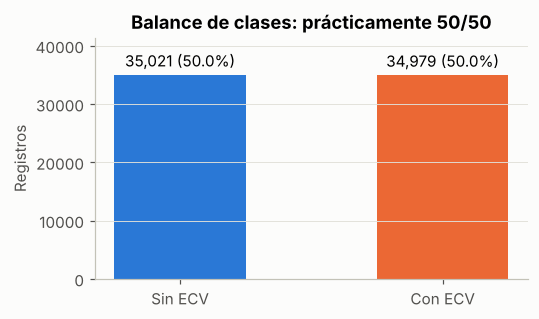

In [ ]:
# Balance de la variable objetivo: decide qué métricas tienen sentido más adelante.
conteo = crudo["cardio"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 3))
barras = ax.bar([NOMBRE_CLASE[i] for i in conteo.index], conteo.values,
                color=[COLOR_CLASE[i] for i in conteo.index], width=0.5)
ax.bar_label(barras, labels=[f"{v:,} ({v/conteo.sum():.1%})" for v in conteo.values], padding=3)
ax.set_title("Balance de clases: prácticamente 50/50")
ax.set_ylabel("Registros"); ax.set_ylim(0, conteo.max() * 1.18); ax.grid(axis="x")
plt.tight_layout(); plt.show()

> 🧭 **Decisión derivada.** Con clases balanceadas, la *exactitud* (accuracy) no es engañosa y no necesitamos sobremuestreo (SMOTE) ni pesos de clase. Aun así reportaremos AUC, sensibilidad y especificidad, porque en salud no cuestan lo mismo los dos tipos de error.

## 3. Calidad de los datos: los errores disfrazados de números

### 3.1 Ver el problema antes de corregirlo

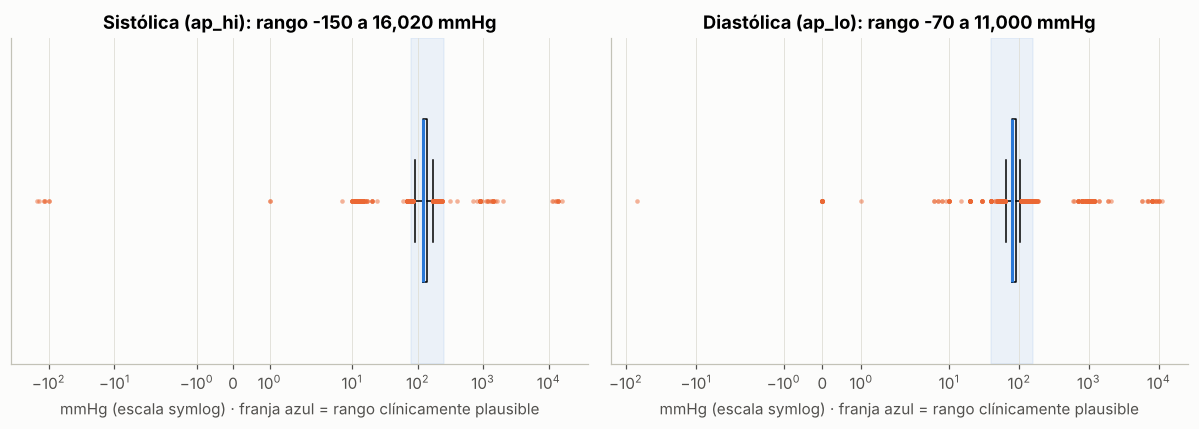

In [ ]:
# Escala symlog: permite ver juntos valores normales (120) y absurdos (16.020) sin ocultar negativos.
fig, ejes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, nombre in zip(ejes, ["ap_hi", "ap_lo"], ["Sistólica (ap_hi)", "Diastólica (ap_lo)"]):
    ax.boxplot(crudo[col], vert=False, widths=0.5, flierprops=dict(marker="o", markersize=3,
               markerfacecolor=NARANJA, markeredgecolor="none", alpha=0.5),
               medianprops=dict(color=AZUL, linewidth=2))
    ax.set_xscale("symlog"); ax.set_yticks([])
    ax.set_title(f"{nombre}: rango {crudo[col].min():,} a {crudo[col].max():,} mmHg")
    ax.axvspan(*( (80, 250) if col == "ap_hi" else (40, 160) ), color=AZUL, alpha=0.08)
    ax.set_xlabel("mmHg (escala symlog) · franja azul = rango clínicamente plausible")
plt.tight_layout(); plt.show()

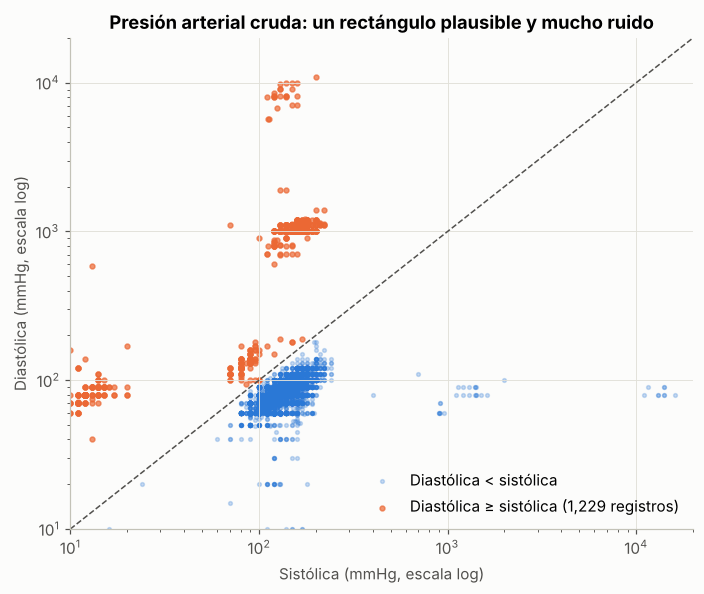

In [ ]:
# Dispersión sistólica vs diastólica: los puntos por encima de la diagonal son imposibles
# (diastólica mayor que sistólica: probablemente columnas invertidas al digitar).
muestra_cruda = crudo[(crudo.ap_hi > 0) & (crudo.ap_lo > 0)]
invertidos = muestra_cruda.ap_lo >= muestra_cruda.ap_hi
fig, ax = plt.subplots(figsize=(6.5, 5.5))
ax.scatter(muestra_cruda.ap_hi[~invertidos], muestra_cruda.ap_lo[~invertidos], s=6, color=AZUL, alpha=0.25, label="Diastólica < sistólica")
ax.scatter(muestra_cruda.ap_hi[invertidos], muestra_cruda.ap_lo[invertidos], s=10, color=NARANJA, alpha=0.7,
           label=f"Diastólica ≥ sistólica ({invertidos.sum():,} registros)")
lim = [10, 2e4]; ax.plot(lim, lim, color=GRIS_OSCURO, lw=1, ls="--")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Sistólica (mmHg, escala log)"); ax.set_ylabel("Diastólica (mmHg, escala log)")
ax.set_title("Presión arterial cruda: un rectángulo plausible y mucho ruido")
ax.legend(loc="lower right"); plt.tight_layout(); plt.show()

### 3.2 Reglas de limpieza y su efecto

Las reglas se definieron con **criterio clínico y no estadístico**. No usamos el rango intercuartílico (IQR), porque eliminaría hipertensos reales (una sistólica de 190 es rara, pero existe y es justo el tipo de paciente que nos interesa). Sí eliminamos lo que es **fisiológicamente imposible**.

> 🧭 **Decisión clave para la sustentación:** *limpiar no es quitar lo raro, es quitar lo imposible.* Un modelo de riesgo cardiovascular que no ve a los pacientes con presión muy alta no sirve.

In [ ]:
tabla_embudo = pd.DataFrame(embudo)
tabla_embudo["% del original eliminado"] = (tabla_embudo["eliminados"] / len(crudo) * 100).round(2)
pd.set_option("display.max_colwidth", 120)
tabla_embudo[["regla", "eliminados", "% del original eliminado", "restantes", "justificacion"]]

,regla,eliminados,% del original eliminado,restantes,justificacion
0,Registros duplicados,24,0.03,69976,Mismo paciente registrado dos veces: inflaría el peso de esos casos.
1,Sistólica fuera de 80–250 mmHg,247,0.35,69729,Por debajo de 80 o por encima de 250 no es compatible con un examen ambulatorio; son errores de digitación (p. ej. 1...
2,Diastólica fuera de 40–160 mmHg,1007,1.44,68722,"Valores como 1000 o 0 son errores de captura, no mediciones."
3,Diastólica ≥ sistólica,82,0.12,68640,Fisiológicamente imposible: la presión diastólica siempre es menor que la sistólica (columnas invertidas).
4,Altura fuera de 130–210 cm,89,0.13,68551,Adultos de 30 a 65 años; alturas de 55 cm o 250 cm son errores.
5,Peso fuera de 35–180 kg,19,0.03,68532,Extremos implausibles para la población estudiada.
6,IMC fuera de 13–60,20,0.03,68512,Combinaciones altura-peso que producen un índice de masa corporal imposible.


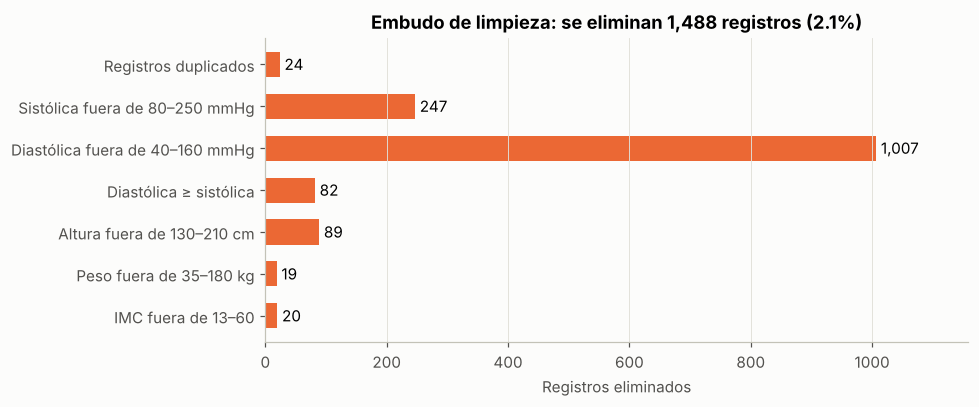

In [ ]:
# Embudo de limpieza: cuánto quita cada regla (aplicadas en secuencia).
fig, ax = plt.subplots(figsize=(9, 3.8))
etiquetas = [e["regla"] for e in embudo][::-1]
valores = [e["eliminados"] for e in embudo][::-1]
barras = ax.barh(etiquetas, valores, color=NARANJA, height=0.6)
ax.bar_label(barras, labels=[f"{v:,}" for v in valores], padding=3)
ax.set_title(f"Embudo de limpieza: se eliminan {len(crudo)-len(datos):,} registros ({1-len(datos)/len(crudo):.1%})")
ax.set_xlabel("Registros eliminados"); ax.grid(axis="y"); ax.set_xlim(0, max(valores) * 1.15)
plt.tight_layout(); plt.show()

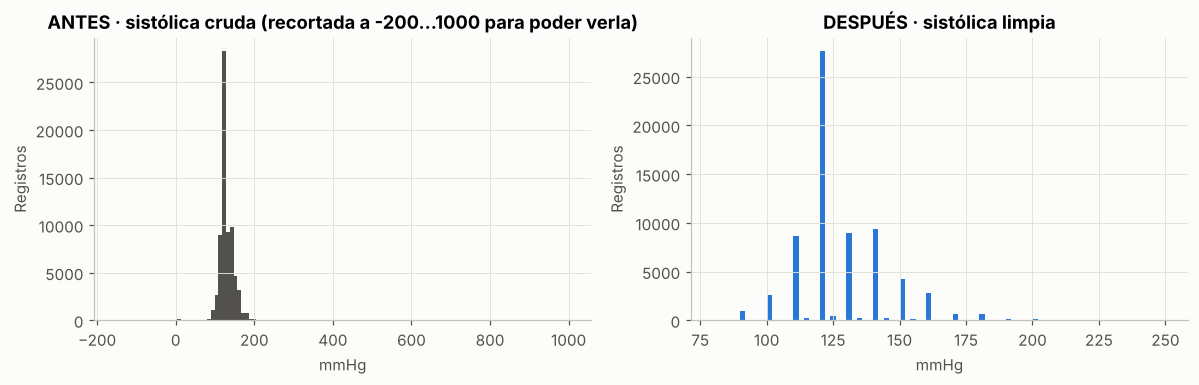

In [ ]:
# Antes y después: la distribución de la sistólica pasa de ilegible a clínicamente interpretable.
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.6))
ejes[0].hist(crudo.ap_hi.clip(-200, 1000), bins=120, color=GRIS_OSCURO)
ejes[0].set_title("ANTES · sistólica cruda (recortada a -200…1000 para poder verla)")
ejes[1].hist(datos.sistolica, bins=np.arange(80, 252, 2), color=AZUL)
ejes[1].set_title("DESPUÉS · sistólica limpia")
for ax in ejes: ax.set_xlabel("mmHg"); ax.set_ylabel("Registros")
plt.tight_layout(); plt.show()

### 3.3 Un hallazgo que no está en ningún enunciado: la preferencia de dígito

Al ver el histograma limpio aparecen "picos" en 120, 130, 140… Quien mide la presión con esfigmomanómetro tiende a **redondear** a múltiplos de 10. Esto tiene consecuencias: la variable se comporta casi como una variable ordinal, y los modelos basados en árboles la cortarán justamente en esos valores.

El 97.1% de las sistólicas termina en 0 (si no hubiera redondeo, sería cerca del 10%).


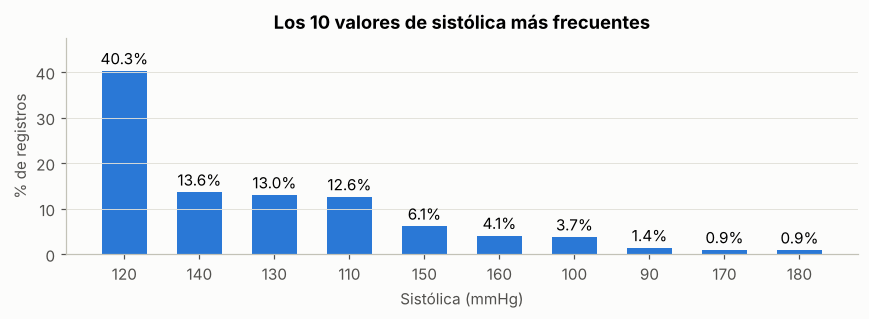

In [ ]:
frecuencia = datos.sistolica.value_counts(normalize=True).head(10)
multiplo_10 = (datos.sistolica % 10 == 0).mean()
print(f"El {multiplo_10:.1%} de las sistólicas termina en 0 (si no hubiera redondeo, sería cerca del 10%).")
fig, ax = plt.subplots(figsize=(8, 3))
barras = ax.bar(frecuencia.index.astype(str), frecuencia.values * 100, color=AZUL, width=0.6)
ax.bar_label(barras, fmt="%.1f%%", padding=2)
ax.set_title("Los 10 valores de sistólica más frecuentes"); ax.set_ylabel("% de registros")
ax.set_xlabel("Sistólica (mmHg)"); ax.grid(axis="x"); ax.set_ylim(0, frecuencia.max() * 118)
plt.tight_layout(); plt.show()

## 4. Variables derivadas

> 🧭 **Por qué derivar variables.** Un médico no piensa en "18.393 días" ni en "62 kg y 168 cm"; piensa en *55 años* y en *IMC 22*. Derivar variables con significado clínico hace el análisis legible y, a veces, mejora el modelo.

- **Edad en años** = días / 365,25
- **IMC** = peso / altura² (kg/m²)
- **Categoría de presión arterial** según la guía ACC/AHA 2017: Normal (<120 y <80), Elevada (120–129 y <80), HTA estadio 1 (130–139 u 80–89), HTA estadio 2 (≥140 o ≥90) y Crisis hipertensiva (>180 o >120).

In [ ]:
datos[["edad", "imc", "sistolica", "diastolica"]].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
edad,68512.0,53.3,6.8,29.6,48.3,53.9,58.4,64.9
imc,68512.0,27.4,5.2,13.5,23.9,26.3,30.1,59.5
sistolica,68512.0,126.7,16.7,80.0,120.0,120.0,140.0,240.0
diastolica,68512.0,81.3,9.4,40.0,80.0,80.0,90.0,160.0


## 5. Análisis univariado y bivariado: ¿qué separa a los dos grupos?

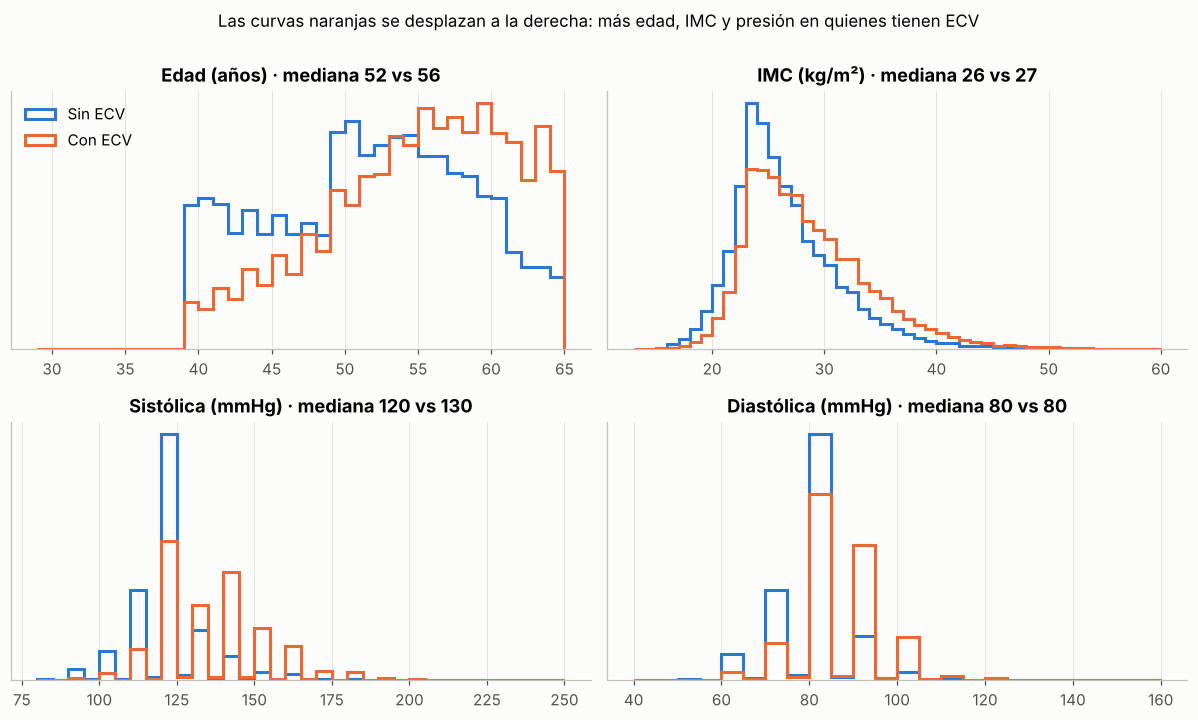

In [ ]:
# Distribuciones de las variables continuas, separadas por clase (densidad para comparar formas).
fig, ejes = plt.subplots(2, 2, figsize=(11, 6.5))
variables = [("edad", "Edad (años)", np.arange(29, 66, 1)), ("imc", "IMC (kg/m²)", np.arange(13, 61, 1)),
             ("sistolica", "Sistólica (mmHg)", np.arange(80, 252, 5)), ("diastolica", "Diastólica (mmHg)", np.arange(40, 162, 5))]
for ax, (col, titulo, bins) in zip(ejes.flat, variables):
    for clase in (0, 1):
        ax.hist(datos.loc[datos.cardio == clase, col], bins=bins, density=True, histtype="step",
                linewidth=2, color=COLOR_CLASE[clase], label=NOMBRE_CLASE[clase])
    medianas = datos.groupby("cardio")[col].median()
    ax.set_title(f"{titulo} · mediana {medianas[0]:.0f} vs {medianas[1]:.0f}")
    ax.set_yticks([])
ejes[0, 0].legend(loc="upper left")
plt.suptitle("Las curvas naranjas se desplazan a la derecha: más edad, IMC y presión en quienes tienen ECV", y=1.0, fontsize=11)
plt.tight_layout(); plt.show()

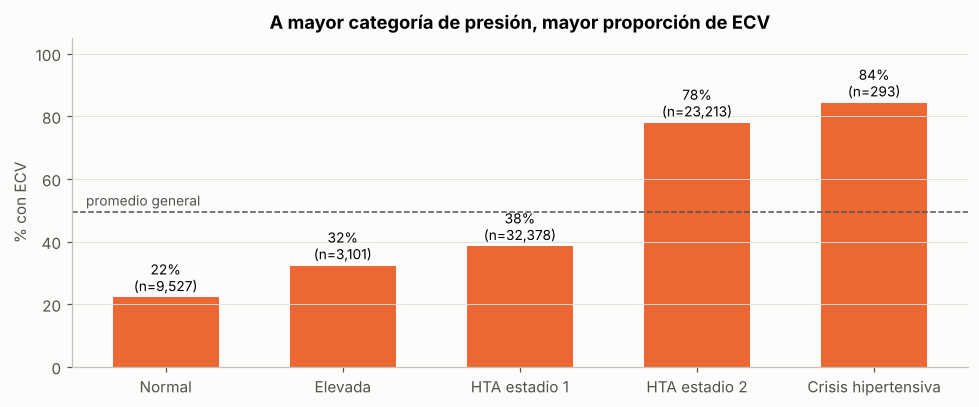

In [ ]:
# Prevalencia de ECV por categoría de presión arterial (ACC/AHA): la relación dosis-respuesta.
prev_pa = datos.groupby("categoria_pa", observed=True)["cardio"].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(9, 3.8))
barras = ax.bar(prev_pa.index.astype(str), prev_pa["mean"] * 100, color=NARANJA, width=0.6)
ax.bar_label(barras, labels=[f"{m:.0%}\n(n={n:,})" for m, n in zip(prev_pa["mean"], prev_pa["size"])], padding=2, fontsize=9)
ax.axhline(datos.cardio.mean() * 100, color=GRIS_OSCURO, ls="--", lw=1)
ax.text(-0.45, datos.cardio.mean() * 100 + 2, "promedio general", ha="left", color=GRIS_OSCURO, fontsize=9)
ax.set_ylim(0, 105); ax.set_ylabel("% con ECV"); ax.grid(axis="x")
ax.set_title("A mayor categoría de presión, mayor proporción de ECV")
plt.tight_layout(); plt.show()

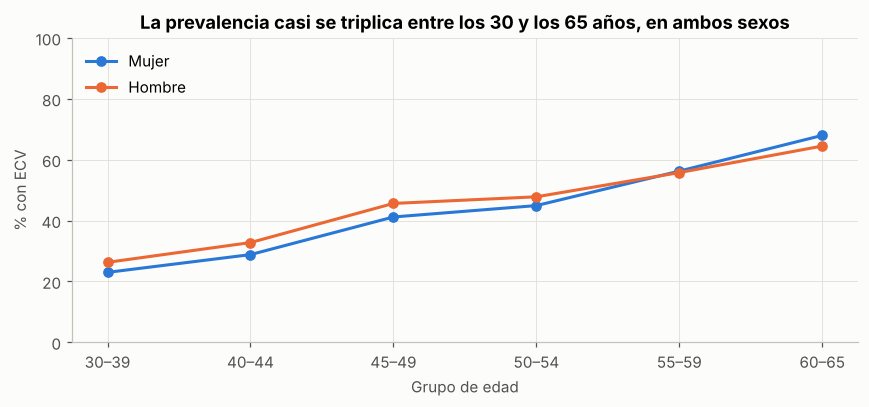

In [ ]:
# Prevalencia por grupo de edad quinquenal, separada por sexo.
datos["grupo_edad"] = pd.cut(datos.edad, bins=[29, 40, 45, 50, 55, 60, 66],
                             labels=["30–39", "40–44", "45–49", "50–54", "55–59", "60–65"], right=False)
prev_edad = datos.groupby(["grupo_edad", "sexo"], observed=True)["cardio"].mean().unstack() * 100
fig, ax = plt.subplots(figsize=(8, 3.8))
for sexo, color in [("Mujer", AZUL), ("Hombre", NARANJA)]:
    ax.plot(prev_edad.index.astype(str), prev_edad[sexo], marker="o", lw=2, color=color, label=sexo)
ax.set_ylabel("% con ECV"); ax.set_xlabel("Grupo de edad"); ax.set_ylim(0, 100)
ax.legend(loc="upper left"); ax.set_title("La prevalencia casi se triplica entre los 30 y los 65 años, en ambos sexos")
plt.tight_layout(); plt.show()

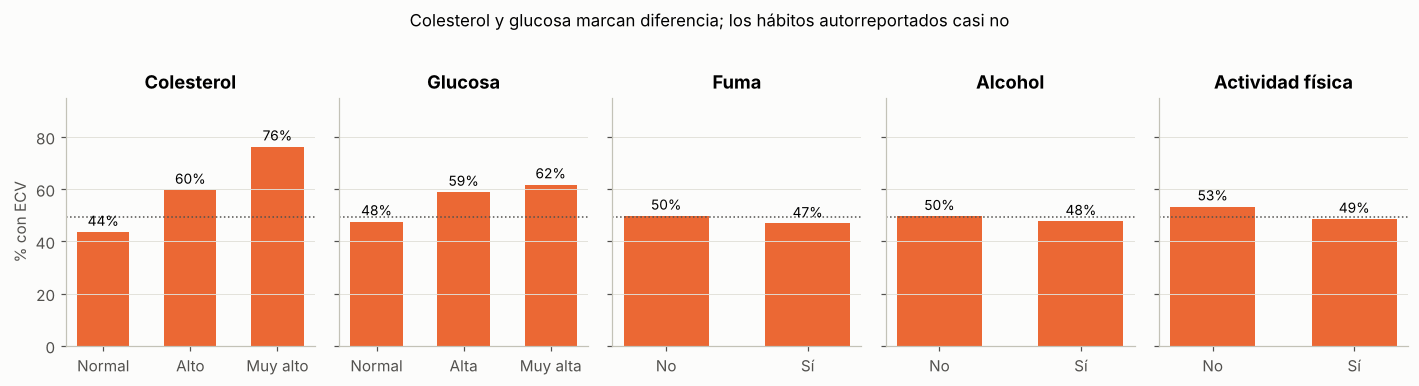

In [ ]:
# Variables categóricas: % con ECV por nivel. Las líneas punteadas marcan el promedio general.
fig, ejes = plt.subplots(1, 5, figsize=(13, 3.4), sharey=True)
categoricas = [("colesterol", "Colesterol", {1: "Normal", 2: "Alto", 3: "Muy alto"}),
               ("glucosa", "Glucosa", {1: "Normal", 2: "Alta", 3: "Muy alta"}),
               ("fuma", "Fuma", {0: "No", 1: "Sí"}), ("alcohol", "Alcohol", {0: "No", 1: "Sí"}),
               ("activo", "Actividad física", {0: "No", 1: "Sí"})]
for ax, (col, titulo, etiquetas) in zip(ejes, categoricas):
    tasa = datos.groupby(col)["cardio"].mean() * 100
    barras = ax.bar([etiquetas[i] for i in tasa.index], tasa.values, color=NARANJA, width=0.6)
    ax.bar_label(barras, fmt="%.0f%%", padding=2, fontsize=9)
    ax.axhline(datos.cardio.mean() * 100, color=GRIS_OSCURO, ls=":", lw=1)
    ax.set_title(titulo); ax.grid(axis="x"); ax.set_ylim(0, 95)
ejes[0].set_ylabel("% con ECV")
plt.suptitle("Colesterol y glucosa marcan diferencia; los hábitos autorreportados casi no", y=1.02, fontsize=11)
plt.tight_layout(); plt.show()

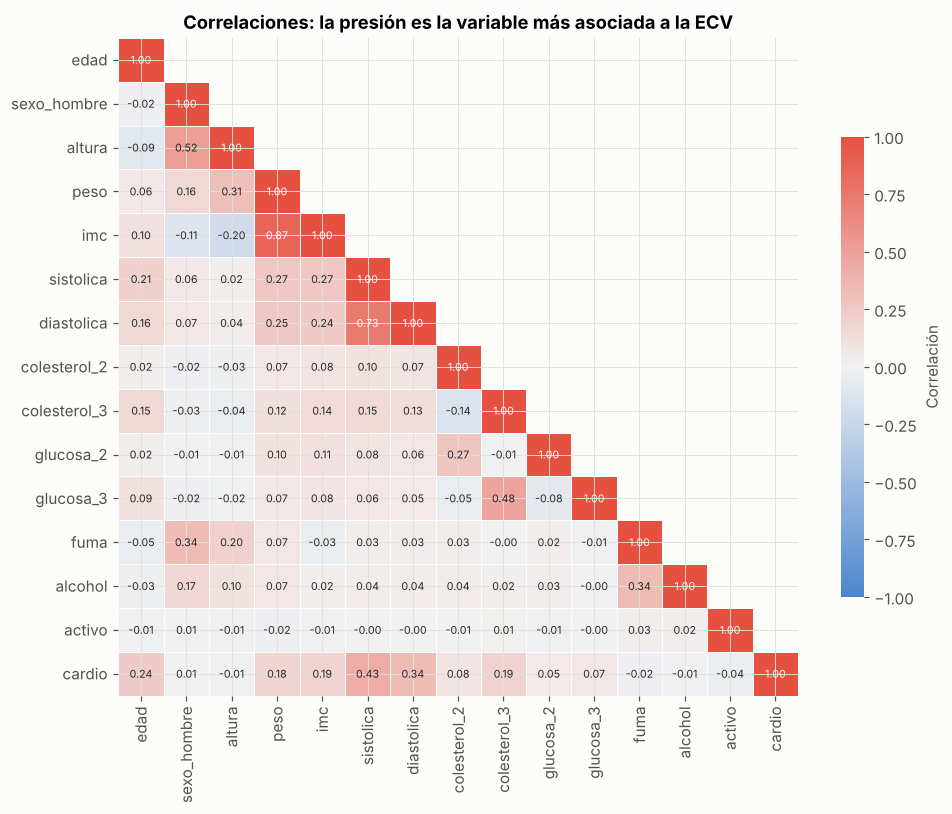

Correlación de cada variable con la ECV (ordenada):
sistolica       0.428
diastolica      0.340
edad            0.240
imc             0.193
colesterol_3    0.193
peso            0.181
colesterol_2    0.081
glucosa_3       0.070
glucosa_2       0.053
sexo_hombre     0.007
alcohol        -0.009
altura         -0.012
fuma           -0.016
activo         -0.038


In [ ]:
# Matriz de correlación (Pearson; con variables binarias equivale a la correlación punto-biserial).
X_corr, _ = matriz_modelo(datos)
corr = X_corr.assign(cardio=datos.cardio).corr()
fig, ax = plt.subplots(figsize=(9, 7.5))
mascara = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mascara, cmap=sns.diverging_palette(250, 15, s=75, l=55, as_cmap=True), center=0,
            vmin=-1, vmax=1, annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5,
            linecolor="#fcfcfb", cbar_kws={"shrink": 0.7, "label": "Correlación"}, ax=ax)
ax.set_title("Correlaciones: la presión es la variable más asociada a la ECV")
plt.tight_layout(); plt.show()
print("Correlación de cada variable con la ECV (ordenada):")
print(corr["cardio"].drop("cardio").sort_values(ascending=False).round(3).to_string())

## 6. Hallazgos del análisis exploratorio

**Calidad de los datos**
1. **Cero nulos no significa datos limpios.** Había presiones negativas y de hasta 16.020 mmHg. Con reglas clínicas se eliminaron **1.488 registros (2,1 %)** y se conservaron **68.512**. La regla que más filas eliminó fue la de diastólica imposible (1.007 casos).
2. **Preferencia de dígito.** El **97,1 %** de las sistólicas termina en cero y el 40 % vale exactamente 120. La presión se registró redondeada, así que se comporta casi como una variable ordinal. Este es un límite del dato, no del modelo.
3. **Clases balanceadas (50/50).** No se requiere rebalanceo.

**Señales de riesgo**

4. **La presión arterial es la señal más fuerte.** La sistólica tiene la mayor correlación con la ECV (0,43). Además hay una relación dosis-respuesta clara: la proporción con ECV pasa de **22 %** en presión normal a **78 %** en HTA estadio 2 y **84 %** en crisis hipertensiva.
5. **La edad es la segunda señal.** La prevalencia sube de alrededor del 25 % entre los 30 y 39 años a cerca del 66 % entre los 60 y 65, con un patrón casi idéntico en hombres y mujeres.
6. **El colesterol y la glucosa también pesan.** Con colesterol muy alto, el 76 % tiene ECV, frente al 44 % con colesterol normal.

**Sorpresas que requieren cautela**

7. **Los hábitos autorreportados casi no diferencian a los grupos**, e incluso los fumadores muestran una tasa levemente *menor* (47 % frente a 50 %). No debe leerse como "fumar protege". Hay dos explicaciones posibles:
   - El subreporte típico de las encuestas.
   - La confusión con el sexo: fumar y ser hombre correlacionan 0,34.
8. **Hay variables redundantes.** El peso y el IMC correlacionan 0,87, y la sistólica y la diastólica, 0,73. Esto no afecta la capacidad predictiva, pero sí la lectura de los coeficientes de la regresión logística. Lo tendremos en cuenta en el Cuaderno 02.

> 🧭 **Qué le pasamos al Cuaderno 02:** datos limpios con reglas justificadas, 14 variables (con colesterol y glucosa en one-hot) y la expectativa de que **la presión, la edad y el colesterol** dominen el modelo. Si el modelo dijera otra cosa, sería una señal de alerta.

## 7. Exportar resultados para el dashboard

> 🧭 **Arquitectura del proyecto.** Los cuadernos *calculan*; el dashboard HTML *observa*. Por eso exportamos agregados y una muestra en JSON en vez de subir 70.000 filas al navegador. El dashboard nunca reentrena: lee lo que los cuadernos produjeron.

In [ ]:
rng = np.random.default_rng(SEMILLA)

# (a) Muestra cruda de presión arterial para el gráfico "antes": todos los registros anómalos + 1.500 normales.
anomalo = ~(crudo.ap_hi.between(80, 250) & crudo.ap_lo.between(40, 160) & (crudo.ap_lo < crudo.ap_hi))
normales = crudo[~anomalo].sample(1500, random_state=SEMILLA)
antes = pd.concat([crudo[anomalo], normales])
presion_cruda = {"sistolica": antes.ap_hi.tolist(), "diastolica": antes.ap_lo.tolist(),
                 "anomalo": anomalo.loc[antes.index].astype(int).tolist()}

# (b) Muestra de 5.000 pacientes limpios para filtros interactivos (estratificada por clase).
muestra = datos.groupby("cardio", group_keys=False).sample(2500, random_state=SEMILLA)
columnas_muestra = ["edad", "sexo", "altura", "peso", "imc", "sistolica", "diastolica",
                    "colesterol", "glucosa", "fuma", "alcohol", "activo", "cardio"]
muestra_json = {c: muestra[c].tolist() for c in columnas_muestra}
muestra_json["categoria_pa"] = muestra["categoria_pa"].astype(str).tolist()

# (c) Prevalencias calculadas sobre TODOS los datos limpios (no sobre la muestra).
def prevalencia(columna):
    t = datos.groupby(columna, observed=True)["cardio"].agg(["mean", "size"])
    return {"nivel": [str(i) for i in t.index], "tasa": t["mean"].round(4).tolist(), "n": t["size"].tolist()}

eda = {
    "meta": {"fuente": "Cardiovascular Disease dataset (S. Ulianova, Kaggle)",
             "n_original": int(len(crudo)), "n_limpio": int(len(datos)),
             "prevalencia": round(float(datos.cardio.mean()), 4),
             "edad_rango": [float(datos.edad.min()), float(datos.edad.max())],
             "pct_sistolica_multiplo_10": round(float(multiplo_10), 4)},
    "embudo": embudo,
    "presion_cruda": presion_cruda,
    "muestra": muestra_json,
    "prevalencia": {"categoria_pa": prevalencia("categoria_pa"), "grupo_edad": prevalencia("grupo_edad"),
                    "colesterol": prevalencia("colesterol"), "glucosa": prevalencia("glucosa"),
                    "fuma": prevalencia("fuma"), "alcohol": prevalencia("alcohol"),
                    "activo": prevalencia("activo"), "sexo": prevalencia("sexo")},
    "correlacion": {"variables": corr.columns.tolist(), "matriz": corr.round(3).values.tolist()},
}
with open(RES("eda.json"), "w", encoding="utf-8") as f:
    json.dump(eda, f, ensure_ascii=False)
ARCHIVOS_EXPORTADOS = [RES("eda.json")]
print(f"eda.json: {os.path.getsize(RES('eda.json'))/1024:.0f} KB")

eda.json: 407 KB


### 7.1 Conjunto depurado en CSV

> 🧭 Se exporta el conjunto limpio con sus variables derivadas para que cualquiera pueda reutilizarlo sin repetir la limpieza. Se conserva el `id` original para rastrear cada fila hasta la fuente.
>
> **Formato pensado para Excel en español (Colombia):** separador `;`, decimales con coma y codificación UTF-8 con BOM. En Python se lee con `pd.read_csv("cardio_depurado.csv", sep=";", decimal=",")`.

In [ ]:
depurado = pd.DataFrame({
    "id": limpio["id"], "edad_dias": limpio["age"], "edad_anios": datos["edad"], "sexo": datos["sexo"],
    "altura_cm": datos["altura"], "peso_kg": datos["peso"], "imc": datos["imc"],
    "sistolica_mmhg": datos["sistolica"], "diastolica_mmhg": datos["diastolica"],
    "categoria_pa": datos["categoria_pa"].astype(str),
    "colesterol": datos["colesterol"], "glucosa": datos["glucosa"],
    "fuma": datos["fuma"], "alcohol": datos["alcohol"], "activo": datos["activo"], "cardio": datos["cardio"],
})
RUTA_DEPURADO = os.path.join(CARPETA_DATOS, "cardio_depurado.csv")
depurado.to_csv(RUTA_DEPURADO, sep=";", decimal=",", index=False, encoding="utf-8-sig")
ARCHIVOS_EXPORTADOS.append(RUTA_DEPURADO)
print(f"cardio_depurado.csv: {len(depurado):,} filas × {depurado.shape[1]} columnas · {os.path.getsize(RUTA_DEPURADO)/1024:.0f} KB")
depurado.head()

cardio_depurado.csv: 68,512 filas × 16 columnas · 4625 KB


,id,edad_dias,edad_anios,sexo,altura_cm,peso_kg,imc,sistolica_mmhg,diastolica_mmhg,categoria_pa,colesterol,glucosa,fuma,alcohol,activo,cardio
0,0,18393,50.4,Hombre,168,62.0,22.0,110,80,HTA estadio 1,1,1,0,0,1,0
1,1,20228,55.4,Mujer,156,85.0,34.9,140,90,HTA estadio 2,3,1,0,0,1,1
2,2,18857,51.6,Mujer,165,64.0,23.5,130,70,HTA estadio 1,3,1,0,0,0,1
3,3,17623,48.2,Hombre,169,82.0,28.7,150,100,HTA estadio 2,1,1,0,0,1,1
4,4,17474,47.8,Mujer,156,56.0,23.0,100,60,Normal,1,1,0,0,0,0


In [ ]:
# Descarga de resultados (solo en Colab). Estos JSON alimentan el dashboard interactivo.
try:
    from google.colab import files
    for archivo in ARCHIVOS_EXPORTADOS:
        files.download(archivo)
except ImportError:
    print("Fuera de Colab: los archivos quedaron en la carpeta", RESULTADOS)

Fuera de Colab: los archivos quedaron en la carpeta ../resultados
